# MobileNetV2 + CBAM pada CIFAR-10
**Tugas Kelompok – Kecerdasan Buatan Lanjut (ST164) – Modern CNN**

## Pertanyaan penelitian
> Di posisi mana CBAM paling efektif dipasang pada MobileNetV2, yaitu yang menaikkan akurasi paling banyak
> dengan tambahan parameter dan komputasi paling kecil, dibandingkan MobileNetV2 asli (baseline)?

## Skenario (satu variabel yang diubah: **posisi CBAM**)
| Skenario | Posisi CBAM | Channel |
|---|---|---|
| `baseline` | tanpa CBAM | - |
| `S1_early` | setelah `features[3]` | 24 |
| `S2_middle` | setelah `features[10]` | 64 |
| `S3_late` | setelah `features[17]` | 320 |


## 1. Setup

In [ ]:
import os, json, time, math, copy, glob, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.models import mobilenet_v2
from torch.utils.flop_counter import FlopCounterMode

warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
USE_AMP = device.type == "cuda"          # mixed precision hanya di GPU
torch.backends.cudnn.benchmark = True

print("torch", torch.__version__, "| device:", device, "|", GPU_NAME)
if device.type == "cpu":
    print("PERINGATAN: GPU tidak aktif. Di Colab: Runtime > Change runtime type > T4 GPU")

torch 2.11.0+cu130 | device: cuda | Tesla T4


In [ ]:
# Simpan hasil ke Google Drive supaya aman kalau Colab terputus
USE_DRIVE = True

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and USE_DRIVE:
    drive.mount("/content/drive")
    RESULT_DIR = "/content/drive/MyDrive/KAL_CBAM_MobileNet"
else:
    RESULT_DIR = "./hasil_cbam"

for sub in ["runs", "arch", "ckpt", "plots"]:
    os.makedirs(f"{RESULT_DIR}/{sub}", exist_ok=True)
print("Hasil disimpan di:", RESULT_DIR)

Mounted at /content/drive
Hasil disimpan di: /content/drive/MyDrive/KAL_CBAM_MobileNet


## 2. Konfigurasi


In [ ]:
QUICK_TEST = False

CFG = dict(
    epochs=30,
    batch_size=128,
    lr=0.1,                 # lr puncak OneCycle
    momentum=0.9,
    weight_decay=5e-4,
    seeds=[0, 1, 2],        # 3 seed -> laporkan rata-rata ± std
    split_seed=42,          # split train/val tetap, sama untuk semua
    n_val=5000,             # 45k train / 5k val / 10k test
    stem_stride=1,
    stage2_stride=1,
    cbam_reduction=16,      # r pada channel attention
    cbam_min_hidden=4,      # batas bawah neuron hidden pada MLP channel attention
    cbam_kernel=7,          # kernel spatial attention
)
if QUICK_TEST:
    CFG.update(epochs=2, seeds=[0])

# Indeks mengacu ke model.features[...] pada torchvision MobileNetV2
SCENARIOS = {
    "baseline":  [],
    "S1_early":  [3],                  # 24 channel
    "S2_middle": [10],                 # 64 channel
    "S3_late":   [17],                 # 320 channel
    "S4_all":    list(range(1, 18)),   # opsional: CBAM di semua blok
}

# Skenario yang DIJALANKAN (training) di sesi Colab ini
MY_SCENARIOS = ["baseline", "S1_early", "S2_middle", "S3_late"]

## 3. Data CIFAR-10


In [ ]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1)


def load_cifar10_arrays(root="./data"):
    tr = datasets.CIFAR10(root, train=True, download=True)
    te = datasets.CIFAR10(root, train=False, download=True)
    return tr.data, np.array(tr.targets), te.data, np.array(te.targets)


def to_gpu(x_np, y_np):
    x = torch.from_numpy(x_np).permute(0, 3, 1, 2).contiguous().to(device)   # uint8, N×3×32×32
    y = torch.from_numpy(y_np).long().to(device)
    return x, y


def random_crop_flip(x, g, pad=4):
    """Random crop (padding `pad`) + horizontal flip, per sampel, semuanya di GPU."""
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device, generator=g)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device, generator=g)
    ar_h = torch.arange(H, device=x.device)
    ar_w = torch.arange(W, device=x.device)
    rows = (i[:, None] + ar_h)[:, None, :, None]
    cols = (j[:, None] + ar_w)[:, None, None, :]
    bidx = torch.arange(B, device=x.device)[:, None, None, None]
    cidx = torch.arange(C, device=x.device)[None, :, None, None]
    out = xp[bidx, cidx, rows, cols]
    flip = torch.rand(B, device=x.device, generator=g) < 0.5
    return torch.where(flip[:, None, None, None], out.flip(3), out)


class GPULoader:
    def __init__(self, x, y, batch_size, train, seed=0):
        self.x, self.y, self.bs, self.train = x, y, batch_size, train
        self.g = torch.Generator(device=x.device)
        self.g.manual_seed(seed)

    def __len__(self):
        n = len(self.x)
        return n // self.bs if self.train else math.ceil(n / self.bs)

    def __iter__(self):
        n = len(self.x)
        if self.train:
            idx = torch.randperm(n, device=self.x.device, generator=self.g)
        else:
            idx = torch.arange(n, device=self.x.device)
        for k in range(len(self)):
            b = idx[k * self.bs:(k + 1) * self.bs]
            xb = (self.x[b].float() / 255.0 - MEAN) / STD
            if self.train:
                xb = random_crop_flip(xb, self.g)
            if device.type == "cuda":
                xb = xb.contiguous(memory_format=torch.channels_last)
            yield xb, self.y[b]

In [ ]:
xtr_np, ytr_np, xte_np, yte_np = load_cifar10_arrays()

# Split tetap: 45.000 train / 5.000 validasi. Test (10.000) hanya dipakai di akhir.
perm = np.random.RandomState(CFG["split_seed"]).permutation(len(xtr_np))
val_idx, train_idx = perm[:CFG["n_val"]], perm[CFG["n_val"]:]

if QUICK_TEST:
    train_idx, val_idx = train_idx[:2000], val_idx[:500]
    xte_np, yte_np = xte_np[:1000], yte_np[:1000]

x_train, y_train = to_gpu(xtr_np[train_idx], ytr_np[train_idx])
x_val, y_val = to_gpu(xtr_np[val_idx], ytr_np[val_idx])
x_test, y_test = to_gpu(xte_np, yte_np)
print(f"train {len(x_train)} | val {len(x_val)} | test {len(x_test)}")

100%|██████████| 170M/170M [02:48<00:00, 1.01MB/s]


train 45000 | val 5000 | test 10000


## 4. Model: CBAM dan MobileNetV2
CBAM = **Channel Attention** (fitur apa yang penting) lalu **Spatial Attention** (di mana lokasinya).

- Channel attention: avg-pool dan max-pool global → MLP bersama (C → C/r → C) → dijumlahkan → sigmoid.
- Spatial attention: rata-rata dan maks sepanjang channel → Conv 7×7 → sigmoid.
- CBAM dipasang **setelah** satu blok `features[p]`, dengan cara membungkusnya: `features[p] = Sequential(blok_asli, CBAM)`.

In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16, min_hidden=4):
        super().__init__()
        hidden = max(channels // reduction, min_hidden)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False),
        )

    def forward(self, x):
        avg = self.mlp(F.adaptive_avg_pool2d(x, 1))
        mx = self.mlp(F.adaptive_max_pool2d(x, 1))
        return torch.sigmoid(avg + mx)                      # B×C×1×1


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        avg = x.mean(dim=1, keepdim=True)
        mx = x.amax(dim=1, keepdim=True)
        return torch.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))   # B×1×H×W


class CBAM(nn.Module):
    def __init__(self, channels, reduction=16, min_hidden=4, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(channels, reduction, min_hidden)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x


def build_model(cbam_positions=(), num_classes=10):
    """MobileNetV2 (dari nol) yang disesuaikan untuk CIFAR-10, dengan CBAM di posisi tertentu."""
    m = mobilenet_v2(weights=None, num_classes=num_classes)
    m.features[0][0].stride = (CFG["stem_stride"],) * 2                   # stem
    if CFG["stage2_stride"] != 2:                                          # downsample pertama di features[2]
        for mod in m.features[2].modules():
            if isinstance(mod, nn.Conv2d) and mod.groups > 1:
                mod.stride = (CFG["stage2_stride"],) * 2
    for p in cbam_positions:
        blk = m.features[p]
        m.features[p] = nn.Sequential(
            blk,
            CBAM(blk.out_channels, CFG["cbam_reduction"], CFG["cbam_min_hidden"], CFG["cbam_kernel"]),
        )
    return m

## 5. Alat ukur: parameter, MACs, waktu inferensi
- **Parameter**: jumlah seluruh bobot yang dilatih.
- **MACs**: dihitung dengan `FlopCounterMode` bawaan PyTorch (konvolusi dan perkalian matriks), input 1×3×32×32.
- **Waktu inferensi**: median dari banyak pengulangan setelah *warm-up*, memakai `cuda.synchronize()` di GPU. Diukur dalam FP32.
  Dilaporkan: CPU batch 1, GPU batch 1 (latensi), GPU batch 256 (throughput).

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_macs(model, input_size=(1, 3, 32, 32)):
    m = copy.deepcopy(model).cpu().eval()
    x = torch.randn(*input_size)
    with torch.no_grad(), FlopCounterMode(display=False) as fcm:
        m(x)
    return fcm.get_total_flops() / 2          # 1 MAC = 2 FLOPs


@torch.inference_mode()
def measure_latency(model, dev, batch_size=1, warmup=30, iters=200):
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(batch_size, 3, 32, 32, device=dev)
    for _ in range(warmup):
        m(x)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    times = []
    for _ in range(iters):
        t0 = time.perf_counter()
        m(x)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000.0)
    return float(np.median(times))             # ms per batch

## 6. Sanity check
Memastikan semua skenario bisa dijalankan, serta melihat ukuran feature map di posisi CBAM.
Spatial attention memakai kernel 7×7

In [ ]:
x = torch.randn(2, 3, 32, 32)
for name, pos in SCENARIOS.items():
    out = build_model(pos).eval()(x)
    assert out.shape == (2, 10), name
print("Semua skenario: forward OK, output", tuple(out.shape))

# Ukuran feature map di posisi-posisi utama
m = build_model([]).eval()
shapes = {}
hooks = [m.features[i].register_forward_hook(lambda mod, inp, out, i=i: shapes.__setitem__(i, tuple(out.shape[1:])))
         for i in (3, 10, 17)]
m(x)
for h in hooks:
    h.remove()
print()
for i in (3, 10, 17):
    C, H, W = shapes[i]
    extra = count_params(CBAM(C, CFG["cbam_reduction"], CFG["cbam_min_hidden"], CFG["cbam_kernel"]))
    print(f"features[{i:2d}] -> C×H×W = {C}×{H}×{W} | tambahan parameter 1 CBAM = {extra:,}")

Semua skenario: forward OK, output (2, 10)

features[ 3] -> C×H×W = 24×32×32 | tambahan parameter 1 CBAM = 290
features[10] -> C×H×W = 64×8×8 | tambahan parameter 1 CBAM = 610
features[17] -> C×H×W = 320×4×4 | tambahan parameter 1 CBAM = 12,898


## 7. Benchmark arsitektur (parameter, MACs, latensi)
File hasilnya masuk ke `RESULT_DIR/arch`.

In [ ]:
def benchmark_arch(name, positions):
    model = build_model(positions)
    info = dict(
        scenario=name, positions=positions, gpu=GPU_NAME, cfg=CFG,
        params=count_params(model),
        macs=count_macs(model),
        lat_cpu_bs1_ms=measure_latency(model, torch.device("cpu"), 1, warmup=20, iters=100),
    )
    if device.type == "cuda":
        info["lat_gpu_bs1_ms"] = measure_latency(model, device, 1, warmup=50, iters=300)
        info["lat_gpu_bs256_ms"] = measure_latency(model, device, 256, warmup=10, iters=50)
    with open(f"{RESULT_DIR}/arch/{name}.json", "w") as f:
        json.dump(info, f, indent=2)
    return info


arch_rows = [benchmark_arch(name, pos) for name, pos in SCENARIOS.items()]
df_arch_now = pd.DataFrame(arch_rows).set_index("scenario")
base = df_arch_now.loc["baseline"]
show = pd.DataFrame({
    "params": df_arch_now.params,
    "Δparams": df_arch_now.params - base.params,
    "Δparams_%": 100 * (df_arch_now.params - base.params) / base.params,
    "MACs_M": df_arch_now.macs / 1e6,
    "ΔMACs_%": 100 * (df_arch_now.macs - base.macs) / base.macs,
    "CPU_bs1_ms": df_arch_now.lat_cpu_bs1_ms,
})
if "lat_gpu_bs1_ms" in df_arch_now:
    show["GPU_bs1_ms"] = df_arch_now.lat_gpu_bs1_ms
    show["GPU_bs256_ms"] = df_arch_now.lat_gpu_bs256_ms
show.round(3)

,params,Δparams,Δparams_%,MACs_M,ΔMACs_%,CPU_bs1_ms,GPU_bs1_ms,GPU_bs256_ms
scenario,,,,,,,,
baseline,2236682,0,0.000,87.976,0.000,10.261,4.797,55.849
S1_early,2236972,290,0.013,88.077,0.115,11.318,5.319,57.709
S2_middle,2237292,610,0.027,87.984,0.008,11.465,5.389,56.617
S3_late,2249580,12898,0.577,88.004,0.031,11.117,5.378,57.247
S4_all,2267532,30850,1.379,88.461,0.551,19.333,12.864,69.161


## 8. Training
- Optimizer SGD (Nesterov), jadwal **OneCycleLR**, mixed precision (GPU), dari nol (tanpa pretrained).
- Epoch terbaik dipilih berdasarkan **akurasi validasi**. Akurasi **test** dihitung sekali pada checkpoint terbaik itu.

In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    n = 0
    for xb, yb in loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction="sum")
        correct += (out.argmax(1) == yb).sum()
        n += len(yb)
    return loss_sum.item() / n, 100.0 * correct.item() / n


def run_experiment(name, seed):
    out_path = f"{RESULT_DIR}/runs/{name}_seed{seed}.json"
    if os.path.exists(out_path):
        print(f"[lewati] {name} seed={seed} sudah ada")
        return
    E = CFG["epochs"]
    positions = SCENARIOS[name]
    print(f"\n=== {name} | seed {seed} | posisi CBAM: {positions or '-'} ===")

    set_seed(seed)
    model = build_model(positions).to(device)
    if device.type == "cuda":
        model = model.to(memory_format=torch.channels_last)

    train_loader = GPULoader(x_train, y_train, CFG["batch_size"], train=True, seed=seed)
    val_loader = GPULoader(x_val, y_val, 512, train=False)
    test_loader = GPULoader(x_test, y_test, 512, train=False)

    opt = torch.optim.SGD(model.parameters(), lr=CFG["lr"], momentum=CFG["momentum"],
                          weight_decay=CFG["weight_decay"], nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], epochs=E,
                                                steps_per_epoch=len(train_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    hist = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[])
    best_val, best_epoch, best_state = -1.0, 0, None
    t0 = time.time()

    for epoch in range(1, E + 1):
        model.train()
        t_loss = torch.zeros((), device=device)
        t_corr = torch.zeros((), device=device)
        n = 0
        for xb, yb in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(xb)
                loss = F.cross_entropy(out, yb)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            t_loss += loss.detach() * len(yb)
            t_corr += (out.argmax(1) == yb).sum()
            n += len(yb)

        tr_loss, tr_acc = t_loss.item() / n, 100.0 * t_corr.item() / n
        va_loss, va_acc = evaluate(model, val_loader)
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc)):
            hist[k].append(v)

        if va_acc > best_val:
            best_val, best_epoch = va_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        if epoch == 1 or epoch == E or epoch % 5 == 0:
            print(f"  ep {epoch:02d}/{E} | train loss {tr_loss:.3f} acc {tr_acc:5.2f} "
                  f"| val loss {va_loss:.3f} acc {va_acc:5.2f} | {time.time() - t0:5.0f}s")

    train_time = time.time() - t0
    model.load_state_dict(best_state)
    te_loss, te_acc = evaluate(model, test_loader)
    print(f"  -> epoch terbaik {best_epoch} | val {best_val:.2f} | TEST {te_acc:.2f}")

    torch.save({k: v.cpu() for k, v in best_state.items()}, f"{RESULT_DIR}/ckpt/{name}_seed{seed}.pt")
    with open(out_path, "w") as f:
        json.dump(dict(scenario=name, positions=positions, seed=seed, cfg=CFG,
                       best_epoch=best_epoch, best_val_acc=best_val,
                       test_acc=te_acc, test_loss=te_loss,
                       train_time_s=train_time, gpu=GPU_NAME, history=hist), f)

## 9. Jalankan eksperimen


In [ ]:
for name in MY_SCENARIOS:
    for seed in CFG["seeds"]:
        run_experiment(name, seed)
print("\nSelesai.")


=== baseline | seed 0 | posisi CBAM: - ===
  ep 01/30 | train loss 1.809 acc 31.68 | val loss 1.648 acc 42.54 |    37s
  ep 05/30 | train loss 0.704 acc 75.73 | val loss 0.804 acc 72.62 |   107s
  ep 10/30 | train loss 0.511 acc 82.47 | val loss 0.516 acc 82.44 |   195s
  ep 15/30 | train loss 0.438 acc 85.02 | val loss 0.453 acc 84.24 |   283s
  ep 20/30 | train loss 0.371 acc 87.29 | val loss 0.383 acc 87.10 |   371s
  ep 25/30 | train loss 0.228 acc 92.24 | val loss 0.290 acc 90.30 |   459s
  ep 30/30 | train loss 0.088 acc 97.20 | val loss 0.219 acc 93.24 |   547s
  -> epoch terbaik 29 | val 93.24 | TEST 92.48

=== baseline | seed 1 | posisi CBAM: - ===
  ep 01/30 | train loss 1.774 acc 32.97 | val loss 1.509 acc 44.16 |    18s
  ep 05/30 | train loss 0.694 acc 76.07 | val loss 0.653 acc 77.62 |    88s
  ep 10/30 | train loss 0.504 acc 82.61 | val loss 0.569 acc 80.92 |   176s
  ep 15/30 | train loss 0.440 acc 84.90 | val loss 0.454 acc 84.38 |   264s
  ep 20/30 | train loss 0.366

## 10. Agregasi hasil
Membaca semua file `.json` di `RESULT_DIR`
Kolom `catatan` hanyalah indikasi kasar: kalau selisih akurasi lebih kecil dari jumlah std baseline dan skenario,
selisihnya bisa jadi hanya noise antar-seed.

In [ ]:
def load_json_dir(sub):
    rows = []
    for f in sorted(glob.glob(f"{RESULT_DIR}/{sub}/*.json")):
        with open(f) as fh:
            rows.append(json.load(fh))
    return rows


runs = load_json_dir("runs")
arch = load_json_dir("arch")
assert runs, "Belum ada hasil training di folder runs/"
assert any(a["scenario"] == "baseline" for a in arch), "Jalankan benchmark arsitektur (sel 7) dulu"

if len({json.dumps(r["cfg"], sort_keys=True) for r in runs}) > 1:
    print("PERINGATAN: ada run dengan CFG berbeda. Perbandingan tidak adil, samakan dulu CFG-nya!\n")

df_runs = pd.DataFrame([{k: r[k] for k in ("scenario", "seed", "best_epoch", "best_val_acc", "test_acc", "train_time_s")}
                        for r in runs])
order = [s for s in SCENARIOS if s in set(df_runs.scenario)]
g = df_runs.groupby("scenario")
summary = pd.DataFrame({
    "n_seed": g.size(),
    "val_acc": g.best_val_acc.mean(),
    "test_acc_mean": g.test_acc.mean(),
    "test_acc_std": g.test_acc.std(),
    "train_time_s": g.train_time_s.mean(),
}).reindex(order)

arch_cols = ["params", "macs", "lat_cpu_bs1_ms", "lat_gpu_bs1_ms", "lat_gpu_bs256_ms"]
df_arch = pd.DataFrame(arch).set_index("scenario").reindex(columns=arch_cols)
full = summary.join(df_arch, how="left")

assert "baseline" in full.index, "Hasil training baseline belum ada"
b = full.loc["baseline"]
full["params_K"] = full.params / 1e3
full["d_params"] = full.params - b.params
full["d_params_%"] = 100 * full.d_params / b.params
full["MACs_M"] = full.macs / 1e6
full["d_MACs_%"] = 100 * (full.macs - b.macs) / b.macs
full["d_acc_pp"] = full.test_acc_mean - b.test_acc_mean                 # selisih dalam poin persen
full["d_lat_cpu_%"] = 100 * (full.lat_cpu_bs1_ms - b.lat_cpu_bs1_ms) / b.lat_cpu_bs1_ms
full["d_lat_gpu1_%"] = 100 * (full.lat_gpu_bs1_ms - b.lat_gpu_bs1_ms) / b.lat_gpu_bs1_ms
noise = full.test_acc_std.fillna(0) + (0 if pd.isna(b.test_acc_std) else b.test_acc_std)
full["catatan"] = np.where(full.index == "baseline", "-",
                           np.where(full.d_acc_pp.abs() <= noise, "dalam noise", "di luar noise"))

table_cols = ["n_seed", "test_acc_mean", "test_acc_std", "d_acc_pp", "catatan",
              "params_K", "d_params", "d_params_%", "MACs_M", "d_MACs_%",
              "lat_cpu_bs1_ms", "d_lat_cpu_%", "lat_gpu_bs1_ms", "d_lat_gpu1_%"]
result_table = full[table_cols].round(3)
result_table.to_csv(f"{RESULT_DIR}/tabel_hasil.csv")
df_runs.sort_values(["scenario", "seed"]).to_csv(f"{RESULT_DIR}/hasil_per_run.csv", index=False)
result_table

,n_seed,test_acc_mean,test_acc_std,d_acc_pp,catatan,params_K,d_params,d_params_%,MACs_M,d_MACs_%,lat_cpu_bs1_ms,d_lat_cpu_%,lat_gpu_bs1_ms,d_lat_gpu1_%
scenario,,,,,,,,,,,,,,
baseline,3,92.270,0.185,0.000,-,2236.682,0.0,0.000,87.976,0.000,10.261,0.000,4.797,0.000
S1_early,3,92.460,0.180,0.190,dalam noise,2236.972,290.0,0.013,88.077,0.115,11.318,10.298,5.319,10.885
S2_middle,3,92.037,0.221,-0.233,dalam noise,2237.292,610.0,0.027,87.984,0.008,11.465,11.733,5.389,12.337
S3_late,3,92.227,0.163,-0.043,dalam noise,2249.580,12898.0,0.577,88.004,0.031,11.117,8.340,5.378,12.112


## 11. Grafik

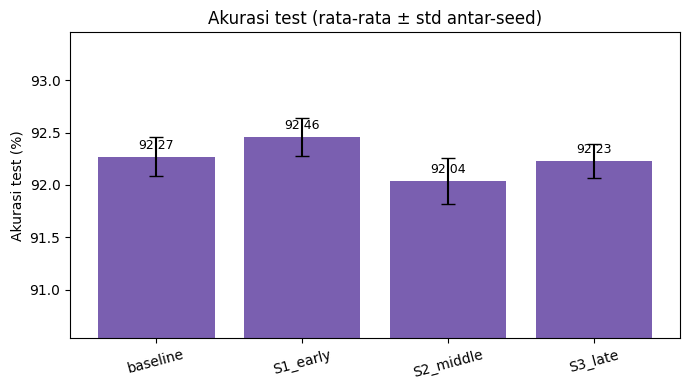

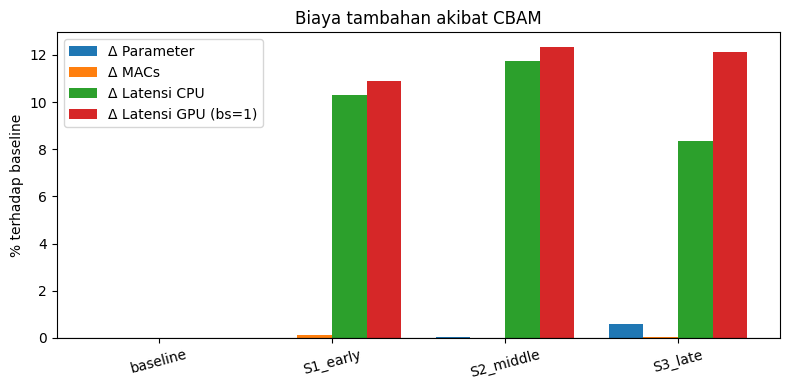

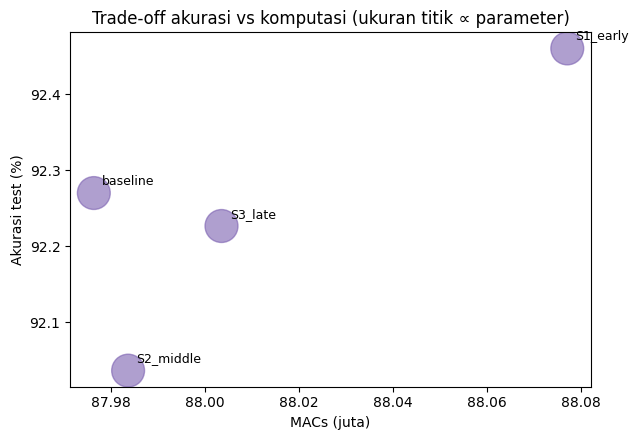

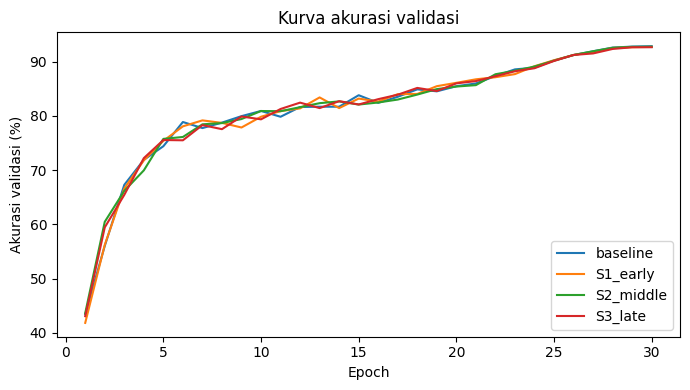

In [ ]:
names = list(full.index)
x_pos = np.arange(len(names))


def save_fig(fig, fname):
    fig.tight_layout()
    fig.savefig(f"{RESULT_DIR}/plots/{fname}", dpi=150)
    plt.show()


# (a) Akurasi test
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x_pos, full.test_acc_mean, yerr=full.test_acc_std.fillna(0), capsize=5, color="#7a5fb0")
for xi, v in zip(x_pos, full.test_acc_mean):
    ax.text(xi, v + 0.05, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
lo, hi = full.test_acc_mean.min(), full.test_acc_mean.max()
ax.set_ylim(lo - 1.5, hi + 1.0)
ax.set_xticks(x_pos)
ax.set_xticklabels(names, rotation=15)
ax.set_ylabel("Akurasi test (%)")
ax.set_title("Akurasi test (rata-rata ± std antar-seed)")
save_fig(fig, "akurasi.png")

# (b) Biaya relatif terhadap baseline
fig, ax = plt.subplots(figsize=(8, 4))
cost_cols = [("d_params_%", "Δ Parameter"), ("d_MACs_%", "Δ MACs"),
             ("d_lat_cpu_%", "Δ Latensi CPU"), ("d_lat_gpu1_%", "Δ Latensi GPU (bs=1)")]
cost_cols = [(c, l) for c, l in cost_cols if full[c].notna().any()]
w = 0.8 / len(cost_cols)
for k, (c, l) in enumerate(cost_cols):
    ax.bar(x_pos + (k - (len(cost_cols) - 1) / 2) * w, full[c].fillna(0), width=w, label=l)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels(names, rotation=15)
ax.set_ylabel("% terhadap baseline")
ax.set_title("Biaya tambahan akibat CBAM")
ax.legend()
save_fig(fig, "biaya.png")

# (c) Trade-off akurasi vs komputasi (ukuran titik ∝ jumlah parameter)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(full.MACs_M, full.test_acc_mean, s=full.params_K / 4, alpha=0.6, color="#7a5fb0")
for n_, xv, yv in zip(names, full.MACs_M, full.test_acc_mean):
    ax.annotate(n_, (xv, yv), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set_xlabel("MACs (juta)")
ax.set_ylabel("Akurasi test (%)")
ax.set_title("Trade-off akurasi vs komputasi (ukuran titik ∝ parameter)")
save_fig(fig, "tradeoff.png")

# (d) Kurva akurasi validasi per epoch (rata-rata antar-seed)
fig, ax = plt.subplots(figsize=(7, 4))
for n_ in names:
    curves = [r["history"]["val_acc"] for r in runs if r["scenario"] == n_]
    L = min(len(c) for c in curves)
    ax.plot(range(1, L + 1), np.mean([c[:L] for c in curves], axis=0), label=n_)
ax.set_xlabel("Epoch")
ax.set_ylabel("Akurasi validasi (%)")
ax.set_title("Kurva akurasi validasi")
ax.legend()
save_fig(fig, "kurva_val.png")

## 12. Visualisasi spatial attention
Menampilkan peta perhatian CBAM pada gambar test: merah/kuning = perhatian tinggi, biru = rendah.


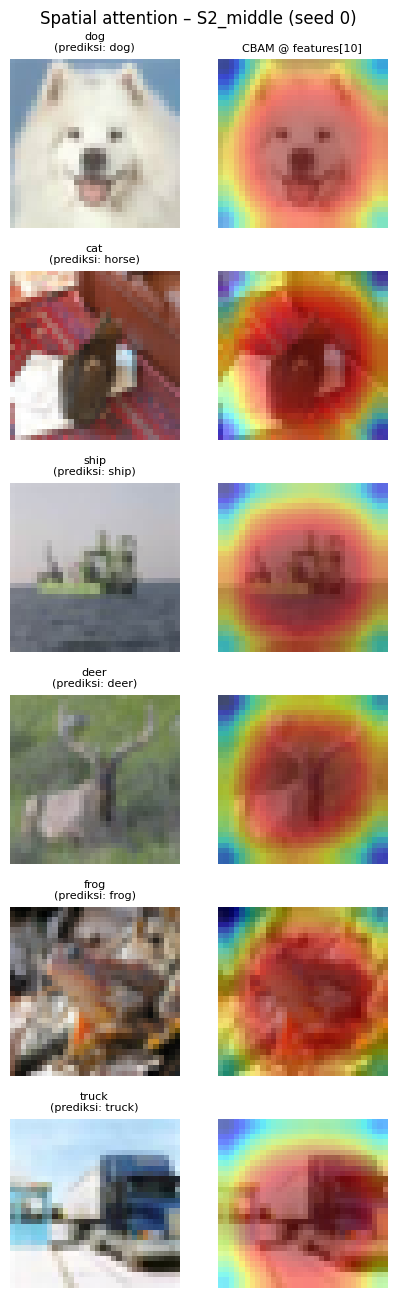

In [ ]:
def visualize_spatial_attention(name, seed=0, n_images=6, max_positions=4):
    positions = SCENARIOS[name]
    assert positions, "Baseline tidak punya CBAM"
    if len(positions) > max_positions:
        positions = [positions[i] for i in np.linspace(0, len(positions) - 1, max_positions).astype(int)]

    full_pos = SCENARIOS[name]
    model = build_model(full_pos).to(device)
    state = torch.load(f"{RESULT_DIR}/ckpt/{name}_seed{seed}.pt", map_location=device)
    model.load_state_dict(state)
    model.eval()

    maps = {}
    hooks = [model.features[p][1].sa.register_forward_hook(
        lambda mod, inp, out, p=p: maps.__setitem__(p, out.detach().float().cpu())) for p in positions]

    idx = np.random.RandomState(0).choice(len(x_test), n_images, replace=False)
    xb = (x_test[idx].float() / 255.0 - MEAN) / STD
    with torch.no_grad():
        pred = model(xb).argmax(1).cpu().numpy()
    for h in hooks:
        h.remove()

    imgs = x_test[idx].permute(0, 2, 3, 1).cpu().numpy()
    labels = y_test[idx].cpu().numpy()
    fig, axes = plt.subplots(n_images, 1 + len(positions), figsize=(2.2 * (1 + len(positions)), 2.2 * n_images),
                             squeeze=False)
    for r in range(n_images):
        axes[r, 0].imshow(imgs[r])
        axes[r, 0].set_title(f"{CLASSES[labels[r]]}\n(prediksi: {CLASSES[pred[r]]})", fontsize=8)
        for c, p in enumerate(positions, start=1):
            att = F.interpolate(maps[p][r:r + 1], size=(32, 32), mode="bilinear", align_corners=False)[0, 0]
            axes[r, c].imshow(imgs[r])
            axes[r, c].imshow(att.numpy(), cmap="jet", alpha=0.5)
            if r == 0:
                axes[r, c].set_title(f"CBAM @ features[{p}]", fontsize=8)
        for c in range(1 + len(positions)):
            axes[r, c].axis("off")
    fig.suptitle(f"Spatial attention – {name} (seed {seed})")
    save_fig(fig, f"spatial_attention_{name}.png")


# Contoh: ganti dengan skenario yang sudah dilatih di sesi/folder ini
if os.path.exists(f"{RESULT_DIR}/ckpt/S2_middle_seed0.pt"):
    visualize_spatial_attention("S2_middle", seed=0)
else:
    print("Checkpoint S2_middle_seed0 belum ada. Ganti nama skenario sesuai yang sudah dilatih.")